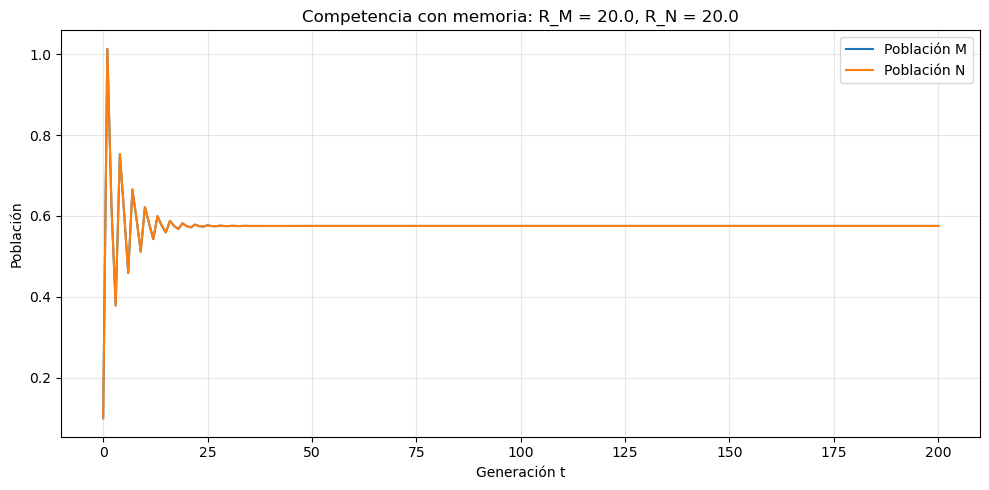

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros de Hassell
c_M = 1.0
c_N = 1.0
q_M = 6.0
q_N = 6.0

# Competencia: N sobre M y M sobre N
alpha = 0.2
beta = 0.2

# Memoria: coeficientes independientes
k = 0.666
p = 0.5

# Condiciones iniciales
M0 = 0.1
N0 = 0.1


def F_M(M, N, R_M):
    return R_M * M / (1 + c_M * M + alpha * N)**q_M


def F_N(N, M, R_N):
    return R_N * N / (1 + c_N * N + beta * M)**q_N


def siguiente(M_ayer, N_ayer, M_hoy, N_hoy, R_M, R_N):
    M_manana = (
        k * F_M(M_hoy, N_hoy, R_M)
        + p * F_M(M_ayer, N_ayer, R_M)
    )
    N_manana = (
        k * F_N(N_hoy, M_hoy, R_N)
        + p * F_N(N_ayer, M_ayer, R_N)
    )
    return M_manana, N_manana


# 1. Evolución temporal
R_M = 20.0
R_N = 20.0
generaciones = 200

M = np.zeros(generaciones + 1)
N = np.zeros(generaciones + 1)

M[0], N[0] = M0, N0
M[1] = F_M(M0, N0, R_M)
N[1] = F_N(N0, M0, R_N)

for t in range(generaciones - 1):
    M[t + 2], N[t + 2] = siguiente(
        M[t], N[t], M[t + 1], N[t + 1], R_M, R_N
    )

plt.figure(figsize=(10, 5))
plt.plot(M, label="Población M")
plt.plot(N, label="Población N")
plt.xlabel("Generación t")
plt.ylabel("Población")
plt.title(f"Competencia con memoria: R_M = {R_M}, R_N = {R_N}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 2. Simulaciones para los diagramas de bifurcación


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_15036\288009900.py:52: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig("bifurcacion_M_N.png", dpi=300, bbox_inches="tight")


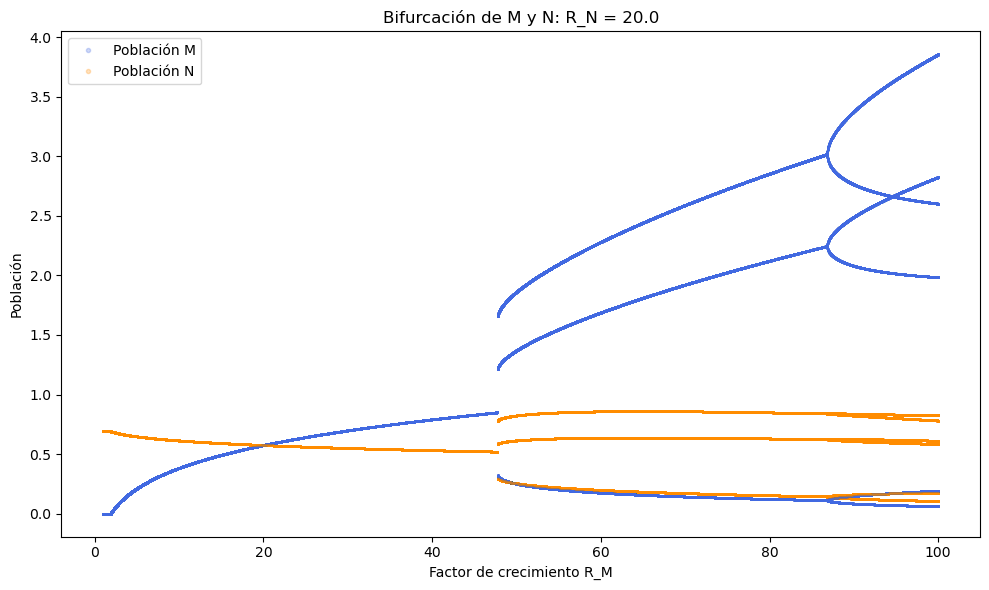

In [8]:
R_valores = np.linspace(1, 100, 5000)
R_N = 20.0  # Se mantiene fijo


M_ayer = np.full_like(R_valores, M0)
N_ayer = np.full_like(R_valores, N0)

M_hoy = F_M(M_ayer, N_ayer, R_valores)
N_hoy = F_N(N_ayer, M_ayer, R_N)

for _ in range(3000):
    M_manana, N_manana = siguiente(
        M_ayer, N_ayer, M_hoy, N_hoy, R_valores, R_N
    )
    M_ayer, M_hoy = M_hoy, M_manana
    N_ayer, N_hoy = N_hoy, N_manana

# Guardar los valores posteriores al transitorio
M_final = np.empty((300, R_valores.size))
N_final = np.empty_like(M_final)

for t in range(300):
    M_manana, N_manana = siguiente(
        M_ayer, N_ayer, M_hoy, N_hoy, R_valores, R_N
    )
    M_ayer, M_hoy = M_hoy, M_manana
    N_ayer, N_hoy = N_hoy, N_manana

    M_final[t] = M_hoy
    N_final[t] = N_hoy


plt.figure(figsize=(10, 6))

for t in range(300):
    plt.plot(
        R_valores, M_final[t],
        ".", color="royalblue", markersize=0.5, alpha=0.25,
        label="Población M" if t == 0 else None
    )
    plt.plot(
        R_valores, N_final[t],
        ".", color="darkorange", markersize=0.5, alpha=0.25,
        label="Población N" if t == 0 else None
    )

plt.xlabel("Factor de crecimiento R_M")
plt.ylabel("Población")
plt.title(f"Bifurcación de M y N: R_N = {R_N}")
plt.legend(markerscale=12)
plt.tight_layout()
plt.savefig("bifurcacion_M_N.png", dpi=300, bbox_inches="tight")
plt.show()